# Garbage Classification — EDA (bản rút gọn)

**Mục tiêu:** hiểu dữ liệu trước khi tiền xử lý và đưa vào CNN — dữ liệu có bao nhiêu ảnh,
có bị lệch lớp không, ảnh có lỗi không, kích thước/định dạng có đồng nhất không, có ảnh trùng lặp không.

**Phạm vi:** chỉ xem và thống kê, không sửa/xóa ảnh, không resize, không augmentation, không chia train/val/test
(các bước đó làm ở notebook tiền xử lý riêng).

Nguồn dữ liệu: [Mostafa Mohamed — Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification).

**Cách chạy:** chỉnh `DATA_DIR` ở ô cấu hình bên dưới trỏ tới thư mục chứa 12 thư mục con (mỗi thư mục là 1 lớp), rồi Run All.


In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Cố định seed để có thể tái lập kết quả lấy mẫu
SEED = 42
rng = np.random.default_rng(SEED)

CLASSES = [
    'battery', 'biological', 'brown-glass', 'cardboard', 'clothes',
    'green-glass', 'metal', 'paper', 'plastic', 'shoes',
    'trash', 'white-glass'
]

# Tìm dữ liệu cả khi chạy từ thư mục dự án hoặc thư mục preprocess
candidates = [
    base / relative
    for base in (Path.cwd(), *Path.cwd().parents)
    for relative in [
        'data/raw/garbage_classification',
        'deep_learning-waste_classification/data/raw/garbage_classification'
    ]
]
DATA_DIR = next((p.resolve() for p in candidates if p.is_dir()), None)

assert DATA_DIR is not None, (
    'Không tìm thấy thư mục dữ liệu garbage_classification. '
    'Hãy kiểm tra lại đường dẫn.'
)

missing = [c for c in CLASSES if not (DATA_DIR / c).is_dir()]
assert not missing, f'Thiếu các thư mục lớp: {missing}'

print('Thư mục dữ liệu:', DATA_DIR)
print('Số lớp:', len(CLASSES))

Thư mục dữ liệu: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\raw\garbage_classification
Số lớp: 12


## 1. Kiểm kê ảnh và phát hiện ảnh lỗi

Với mỗi ảnh: đọc thử bằng PIL, ghi lại lớp (tên thư mục), kích thước, định dạng, chế độ màu (mode) và dung lượng file.
Ảnh không mở được sẽ được liệt kê riêng để nhóm biết mà loại ra khi tiền xử lý — **không tự động xóa** ở bước EDA.


In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png'}  # thêm đuôi khác vào đây nếu dataset của bạn có

records = []
for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    label = class_dir.name
    for img_path in class_dir.iterdir():
        if img_path.suffix.lower() not in EXTENSIONS:
            continue
        try:
            with Image.open(img_path) as im:
                im.verify()  # kiểm tra file có bị hỏng không, chưa load pixel
            with Image.open(img_path) as im:  # verify() làm file "dùng 1 lần", nên mở lại để đọc info
                width, height = im.size
                fmt, mode = im.format, im.mode
            records.append({
                'filepath': str(img_path.relative_to(DATA_DIR)),
                'label': label,
                'width': width,
                'height': height,
                'format': fmt,
                'mode': mode,
                'size_kb': img_path.stat().st_size / 1024,
                'error': None,
            })
        except Exception as exc:
            # Ảnh lỗi vẫn được ghi lại (kèm lý do) để không bị "mất dấu"
            records.append({
                'filepath': str(img_path.relative_to(DATA_DIR)),
                'label': label,
                'width': None, 'height': None, 'format': None, 'mode': None,
                'size_kb': img_path.stat().st_size / 1024,
                'error': f'{type(exc).__name__}: {exc}',
            })

df = pd.DataFrame(records)
valid = df[df.error.isna()].copy()

print(f'Tổng số ảnh: {len(df):,}')
print(f'Đọc được: {len(valid):,}')
print(f'Lỗi: {len(df) - len(valid):,}')

errors = df[df.error.notna()]
if len(errors):
    display(errors[['filepath', 'label', 'error']])
else:
    print('Không có ảnh lỗi.')


Tổng số ảnh: 15,515
Đọc được: 15,515
Lỗi: 0
Không có ảnh lỗi.


## 2. Phân bố lớp (kiểm tra mất cân bằng dữ liệu)

Đếm số ảnh mỗi lớp. Nếu các lớp lệch nhau nhiều, cần lưu ý khi huấn luyện (ví dụ: dùng class weights,
hoặc không chỉ nhìn accuracy mà phải xem thêm precision/recall/F1 theo từng lớp).


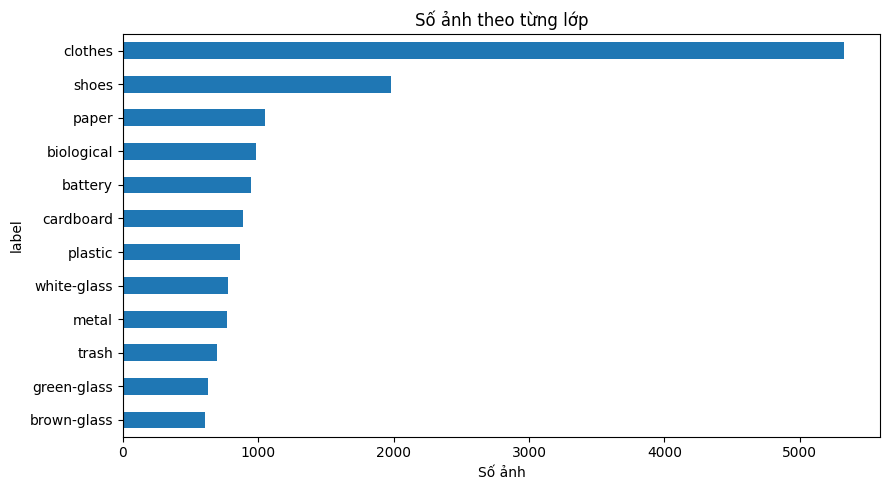

Lớp nhiều ảnh nhất: clothes (5325 ảnh)
Lớp ít ảnh nhất: brown-glass (607 ảnh)
Tỉ lệ lệch (max/min): 8.77 lần


In [3]:
counts = valid['label'].value_counts().reindex(CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
counts.sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Số ảnh')
ax.set_title('Số ảnh theo từng lớp')
plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f'Lớp nhiều ảnh nhất: {counts.idxmax()} ({counts.max()} ảnh)')
print(f'Lớp ít ảnh nhất: {counts.idxmin()} ({counts.min()} ảnh)')
print(f'Tỉ lệ lệch (max/min): {imbalance_ratio:.2f} lần')


## 3. Xem ảnh mẫu theo từng lớp

Lấy ngẫu nhiên vài ảnh mỗi lớp (seed cố định) để quan sát bằng mắt: vật thể có rõ không, nền là gì,
màu sắc/hình dạng có gì đặc biệt, có ảnh nào trông như bị gán nhầm lớp không.


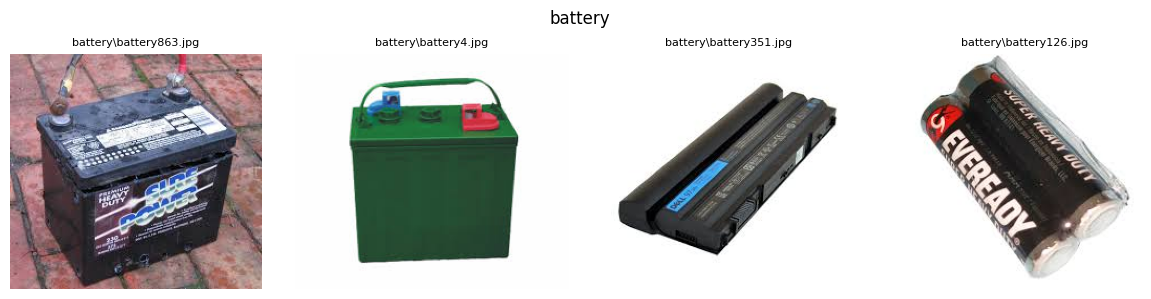

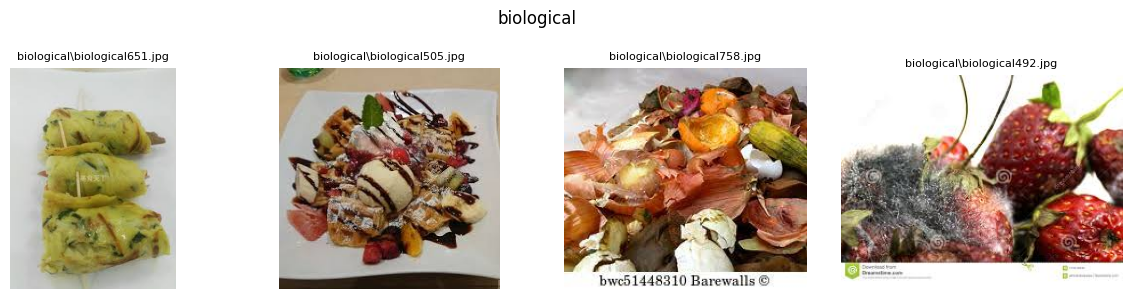

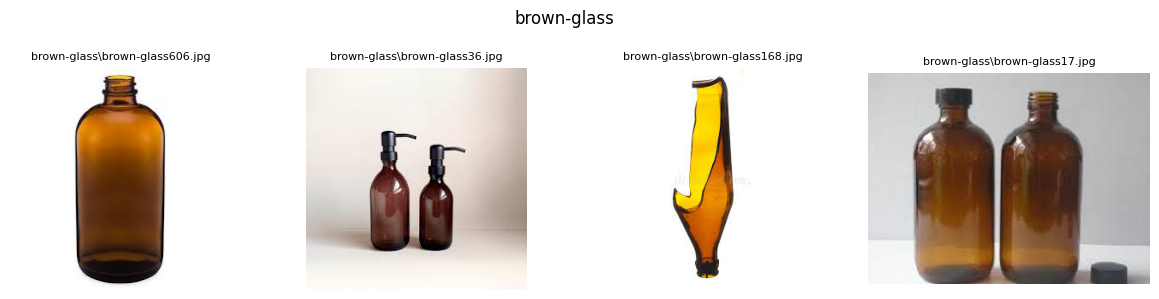

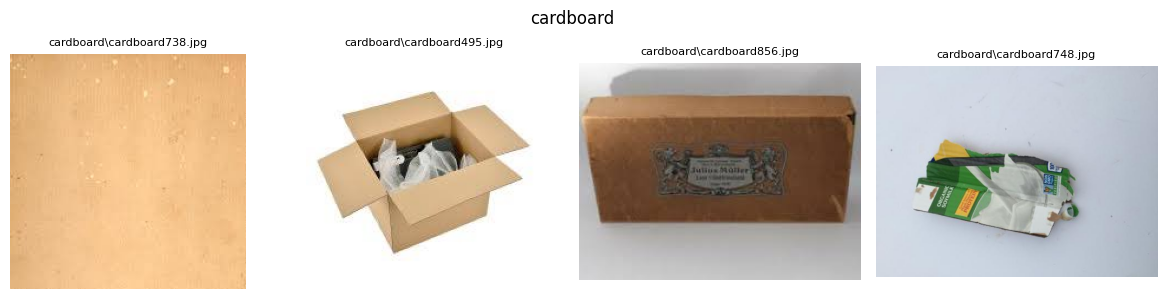

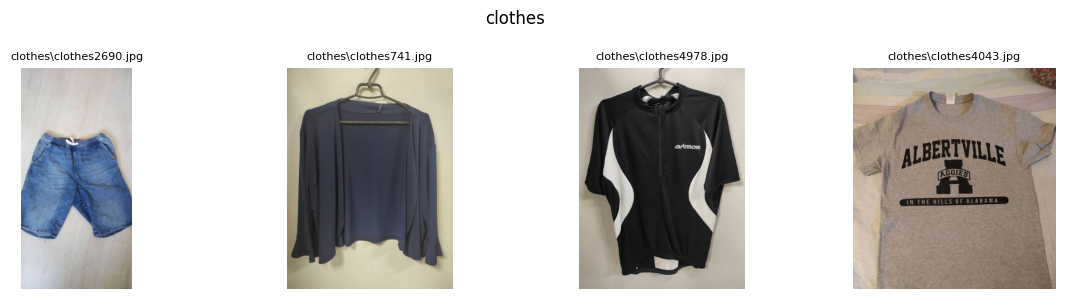

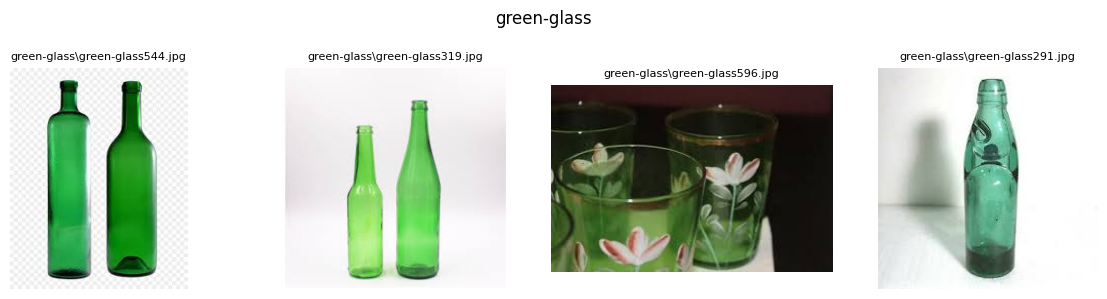

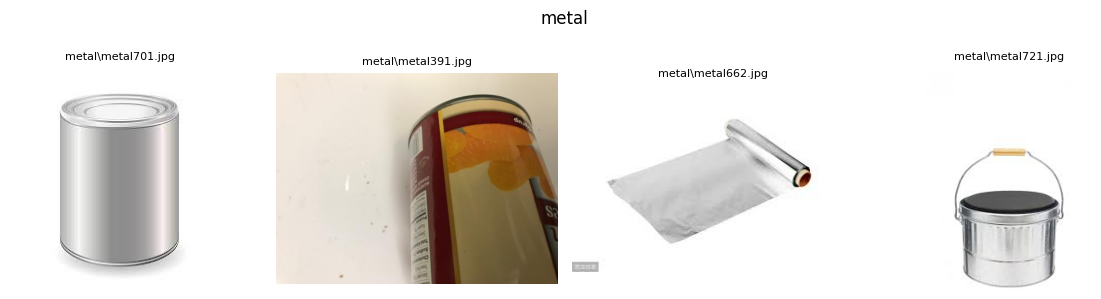

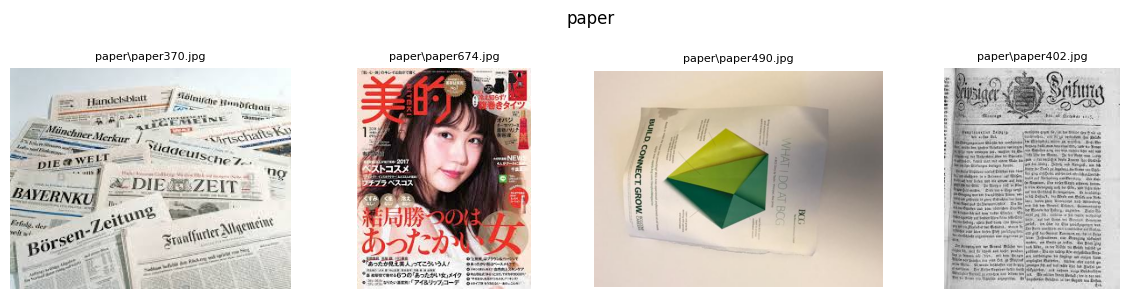

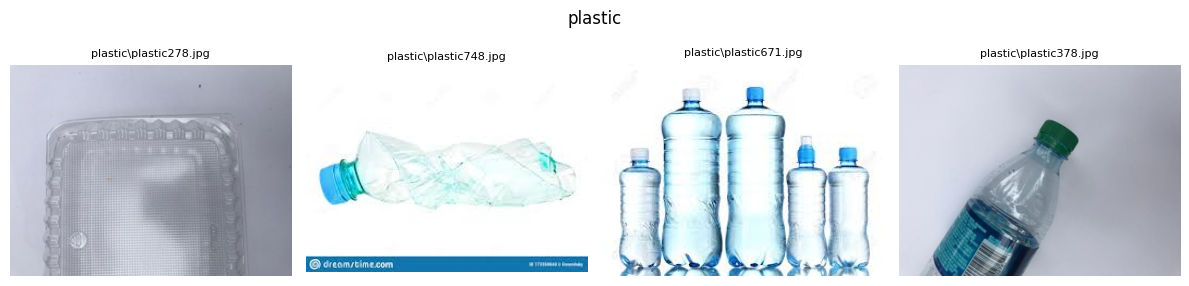

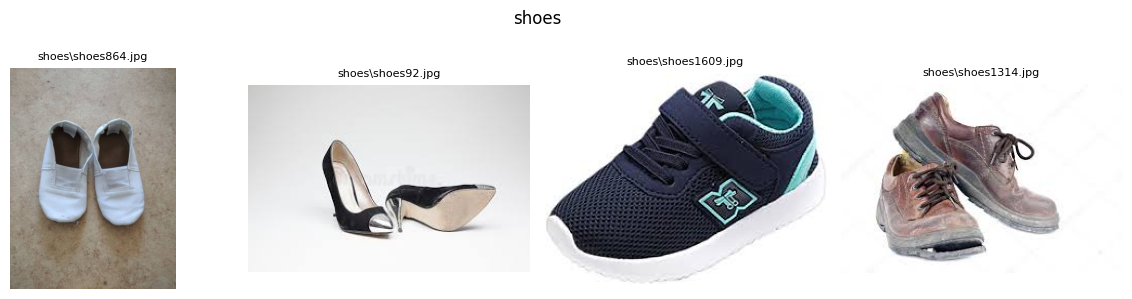

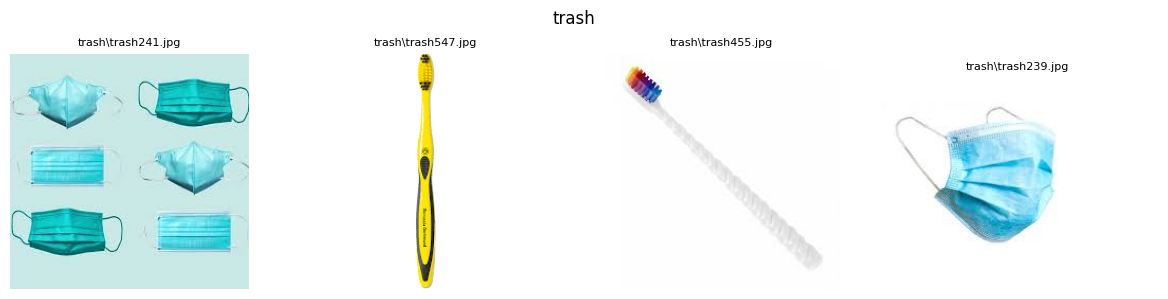

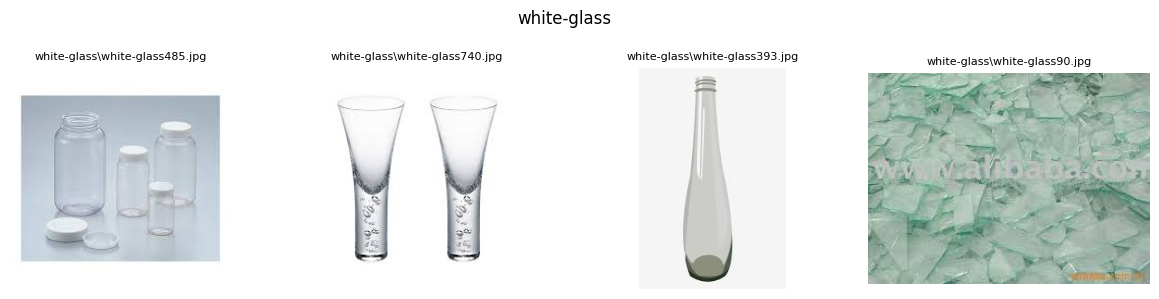

In [4]:
def show_samples(label, n=4):
    subset = valid[valid.label == label]
    sample = subset.sample(n=min(n, len(subset)), random_state=SEED)
    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample.iterrows()):
        with Image.open(DATA_DIR / row.filepath) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(row.filepath.split('/')[-1], fontsize=8)
        ax.axis('off')
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()

for c in CLASSES:
    show_samples(c, n=4)


## 4. Kích thước và định dạng ảnh

Cần biết trước khi tiền xử lý: ảnh có cùng kích thước không (nếu không thì bắt buộc phải resize),
có nhiều định dạng (JPEG/PNG...) hay nhiều mode màu (RGB/L/RGBA...) không (nếu có, cần convert về cùng
1 định dạng, ví dụ RGB, trước khi đưa vào model).


Số kích thước (width, height) khác nhau: 892
Các định dạng ảnh: ['JPEG', 'PNG']
Các mode màu: ['P', 'RGB']


,width,height
count,15515.000000,15515.000000
mean,349.822301,351.705833
std,117.548544,149.418487
min,51.000000,100.000000
25%,234.000000,224.000000
50%,400.000000,384.000000
75%,400.000000,533.000000
max,888.000000,936.000000


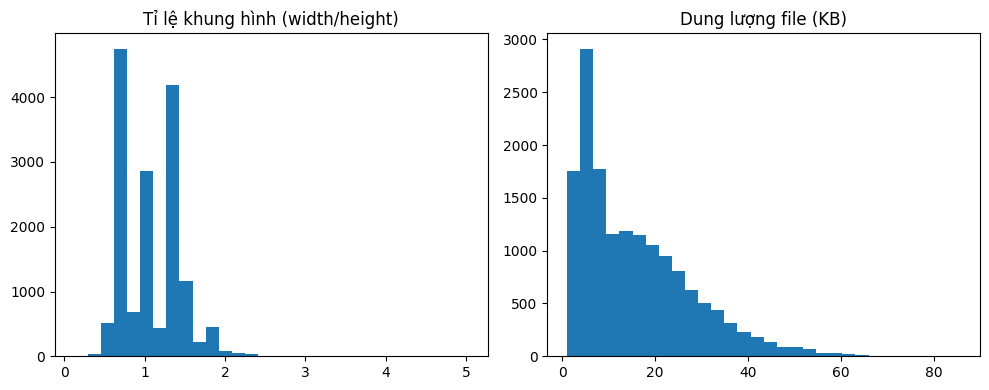

In [5]:
print('Số kích thước (width, height) khác nhau:', valid[['width', 'height']].drop_duplicates().shape[0])
print('Các định dạng ảnh:', sorted(valid['format'].unique()))
print('Các mode màu:', sorted(valid['mode'].unique()))

display(valid[['width', 'height']].describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(valid.width / valid.height, bins=30)
axes[0].set_title('Tỉ lệ khung hình (width/height)')
axes[1].hist(valid.size_kb, bins=30)
axes[1].set_title('Dung lượng file (KB)')
plt.tight_layout()
plt.show()


## 5. Kiểm tra ảnh trùng lặp

Chỉ kiểm tra **trùng hoàn toàn** (giống nhau từng byte) bằng hàm băm SHA-256: hai file cho ra cùng
một chuỗi hash thì chắc chắn là cùng một ảnh. Cách này đơn giản, dễ giải thích và đủ để phát hiện
tình trạng ảnh bị tải trùng — nếu ảnh trùng lặp rơi vào cả tập train và test/val sau này sẽ làm
đánh giá mô hình bị sai lệch (data leakage).

*(Không tìm ảnh "gần giống nhau" — việc đó cần thuật toán phức tạp hơn nhiều và không bắt buộc cho bài này.)*


In [6]:
def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

valid['file_hash'] = [file_hash(DATA_DIR / p) for p in valid['filepath']]

# Gom các ảnh có cùng hash thành từng nhóm, đánh số group_id để dễ theo dõi/trích dẫn trong báo cáo
dup_hashes = valid['file_hash'].value_counts()
dup_hashes = dup_hashes[dup_hashes > 1].index.tolist()

groups = []
for i, h in enumerate(dup_hashes, start=1):
    members = valid.loc[valid.file_hash == h, ['filepath', 'label']]
    groups.append({
        'group_id': f'group_{i:03d}',
        'n_images': len(members),
        'labels': sorted(members.label.unique()),
        'cross_label': members.label.nunique() > 1,  # True = các ảnh trùng nhau nhưng bị gán khác lớp -> cần xem trước
        'files': members['filepath'].tolist(),
    })

n_groups = len(groups)
n_redundant = sum(g['n_images'] for g in groups) - n_groups

print(f'Số nhóm ảnh trùng hoàn toàn: {n_groups}')
print(f'Số ảnh dư ra nếu mỗi nhóm chỉ giữ 1 ảnh: {n_redundant}')

# Bảng tổng quan: mỗi dòng là 1 nhóm, liệt kê luôn danh sách file trong nhóm đó
if n_groups:
    overview = pd.DataFrame(groups)[['group_id', 'n_images', 'labels', 'cross_label', 'files']]
    display(overview)
else:
    print('Không phát hiện ảnh trùng lặp hoàn toàn.')


Số nhóm ảnh trùng hoàn toàn: 18
Số ảnh dư ra nếu mỗi nhóm chỉ giữ 1 ảnh: 19


,group_id,n_images,labels,cross_label,files
0,group_001,3,[green-glass],False,"[green-glass\green-glass413.jpg, green-glass\g..."
1,group_002,2,[clothes],False,"[clothes\clothes2051.jpg, clothes\clothes5234...."
2,group_003,2,[green-glass],False,"[green-glass\green-glass231.jpg, green-glass\g..."
3,group_004,2,[green-glass],False,"[green-glass\green-glass285.jpg, green-glass\g..."
4,group_005,2,[green-glass],False,"[green-glass\green-glass292.jpg, green-glass\g..."
5,group_006,2,[green-glass],False,"[green-glass\green-glass336.jpg, green-glass\g..."
6,group_007,2,[green-glass],False,"[green-glass\green-glass349.jpg, green-glass\g..."
7,group_008,2,[green-glass],False,"[green-glass\green-glass388.jpg, green-glass\g..."
8,group_009,2,[green-glass],False,"[green-glass\green-glass403.jpg, green-glass\g..."
9,group_010,2,[green-glass],False,"[green-glass\green-glass422.jpg, green-glass\g..."


Bảng trên cho thấy từng nhóm ảnh trùng nhau và danh sách file cụ thể. Ô dưới hiển thị luôn hình ảnh của từng nhóm để xác nhận bằng mắt — đặc biệt chú ý nhóm có `cross_label = True` (ảnh giống hệt nhau nhưng lại nằm ở 2 lớp khác nhau).

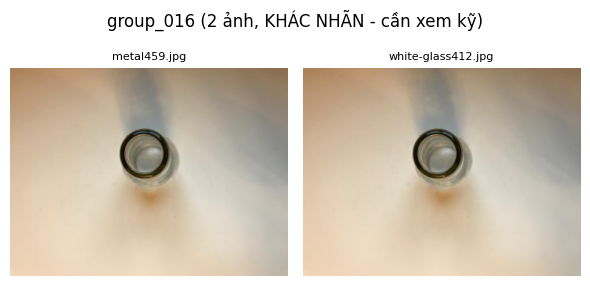

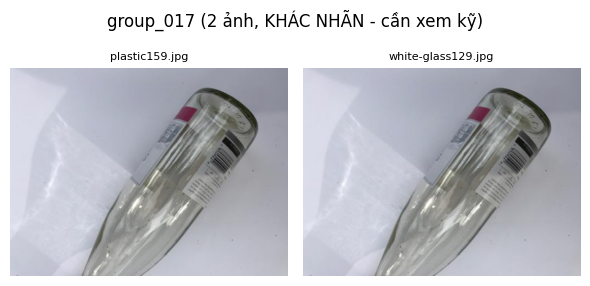

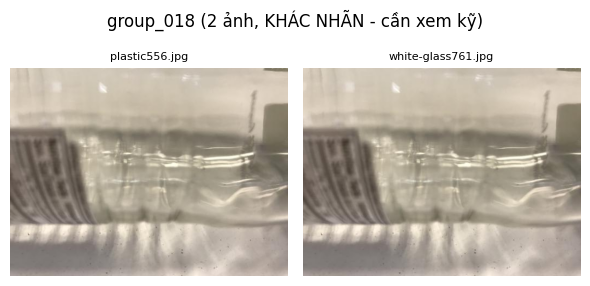

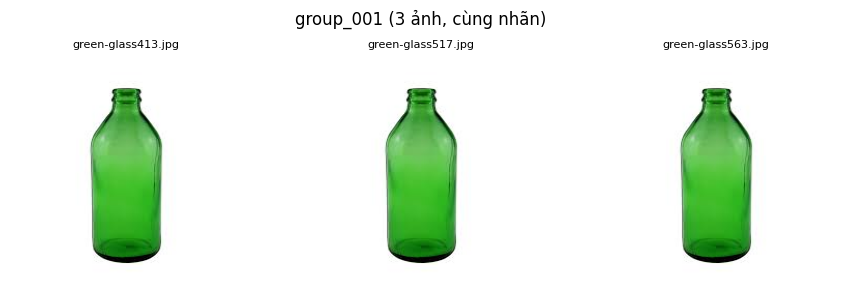

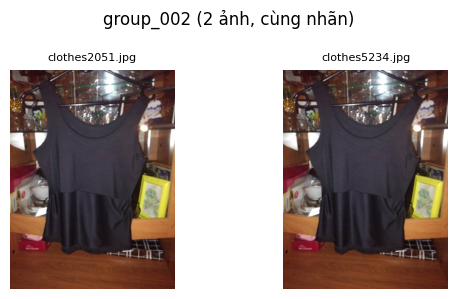

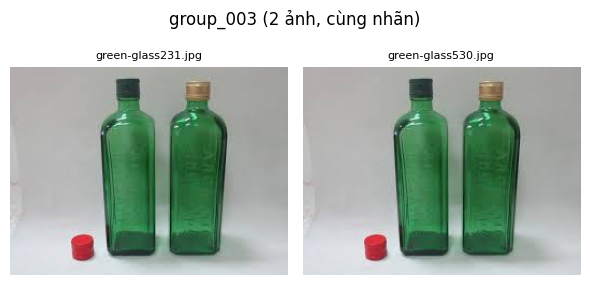

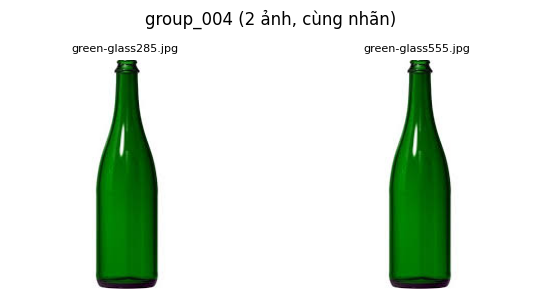

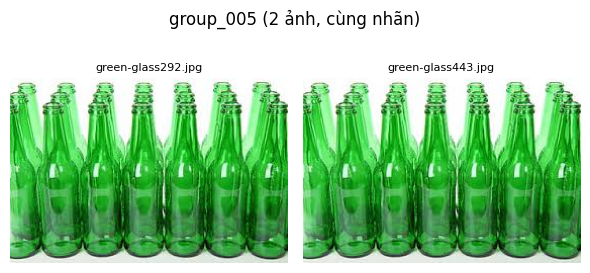

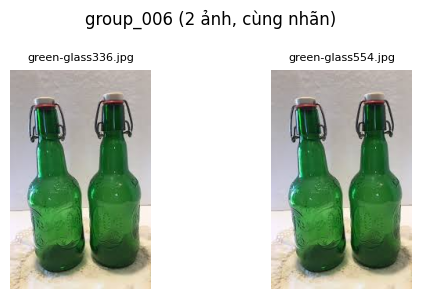

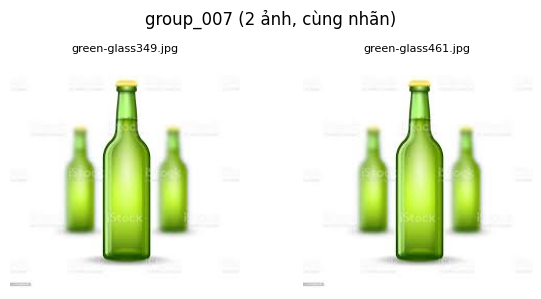

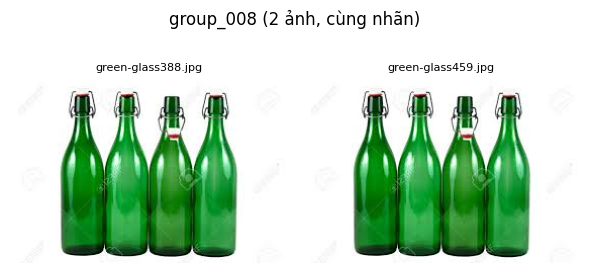

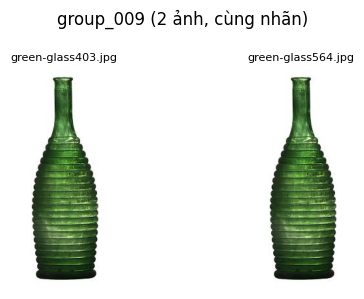

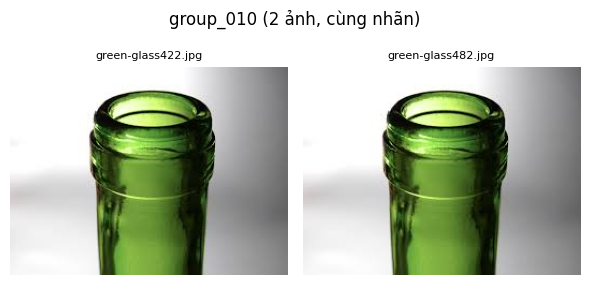

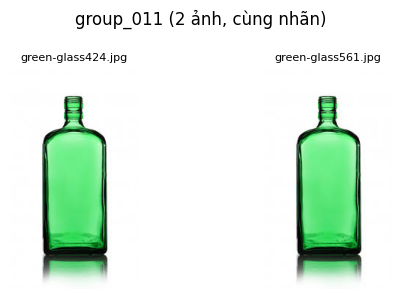

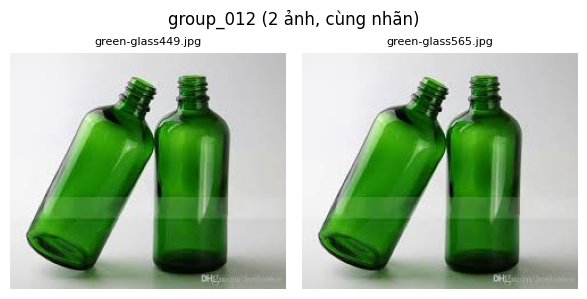

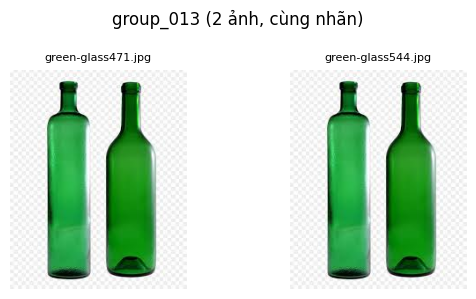

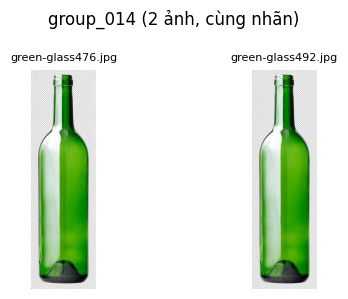

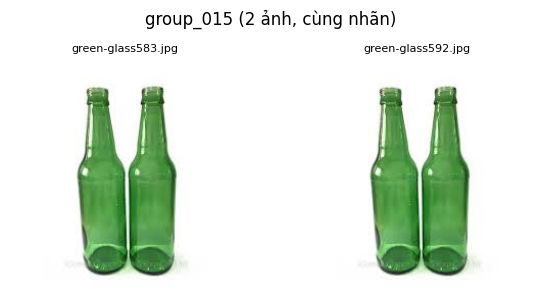

In [9]:
# Xem trực tiếp từng nhóm bằng ảnh, để xác nhận bằng mắt (không chỉ nhìn tên file)
# Ưu tiên xem các nhóm cross_label=True trước, vì đó là dấu hiệu khả năng gán nhầm nhãn
def show_group(group, max_cols=6):
    files = group['files'][:max_cols]
    fig, axes = plt.subplots(1, len(files), figsize=(3 * len(files), 3))
    if len(files) == 1:
        axes = [axes]
    for ax, fp in zip(axes, files):
        with Image.open(DATA_DIR / fp) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(Path(fp).name, fontsize=8)
        ax.axis('off')
    tag = 'KHÁC NHÃN - cần xem kỹ' if group['cross_label'] else 'cùng nhãn'
    fig.suptitle(f"{group['group_id']} ({group['n_images']} ảnh, {tag})")
    plt.tight_layout()
    plt.show()

groups_sorted = sorted(groups, key=lambda g: (not g['cross_label'], g['group_id']))
MAX_GROUPS_TO_SHOW = 20  # tăng/giảm số này nếu muốn xem nhiều/ít nhóm hơn

for g in groups_sorted[:MAX_GROUPS_TO_SHOW]:
    show_group(g)

if n_groups > MAX_GROUPS_TO_SHOW:
    print(f'... còn {n_groups - MAX_GROUPS_TO_SHOW} nhóm nữa, tăng MAX_GROUPS_TO_SHOW để xem thêm.')


## 6. Tổng kết

Ghi lại nhanh các điểm cần lưu ý cho bước tiền xử lý, dựa trên kết quả chạy phía trên.


In [8]:
print('=== TỔNG KẾT EDA ===')
print(f'- Tổng ảnh: {len(df):,}, đọc được: {len(valid):,}, lỗi: {len(df) - len(valid):,}')
print(f'- Số lớp: {len(CLASSES)}, lệch lớp (max/min): {imbalance_ratio:.2f} lần')
print(f'- Số kích thước ảnh khác nhau: {valid[["width", "height"]].drop_duplicates().shape[0]}')
print(f'- Định dạng: {sorted(valid["format"].unique())}, mode màu: {sorted(valid["mode"].unique())}')
print(f'- Số nhóm ảnh trùng hoàn toàn: {n_groups}')


=== TỔNG KẾT EDA ===
- Tổng ảnh: 15,515, đọc được: 15,515, lỗi: 0
- Số lớp: 12, lệch lớp (max/min): 8.77 lần
- Số kích thước ảnh khác nhau: 892
- Định dạng: ['JPEG', 'PNG'], mode màu: ['P', 'RGB']
- Số nhóm ảnh trùng hoàn toàn: 18
